In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import math


1. Implement a general continued fraction evaluator that takes an and bn as functions of n
and a truncation depth N , using the backward recurrence.

In [3]:
#question 1
def continued_fraction(a, b, N):

    answer = b(N)

    for n in range(N-1, 0, -1):
        answer = b(n) + a(n+1) / answer

    return b(0) + a(1) / answer


#this is an example of a continued fraction where a(n) = 1 and b(n) = n + 1. 
a = lambda n: 1
b = lambda n: n + 1
answer = continued_fraction(a, b, 3)
print("Continued fraction answer:", answer)

Continued fraction answer: 1.4333333333333333


2. Implement at least 5 constants with continued fraction formulas, for example π, e, √2,
the golden ratio, ln 2, ζ(2), ζ(3) and Catalan’s constant. Use the sources below [1, 2, 3, 4, 5]
and cite the source of every formula you use.

In [4]:
#question 2-used question 1 to find the continued fraction for pi, e, sqrt(2), golden ratio and ln(2)
#used sources [1], [3], and [5] to find the continued fractions for these numbers.
def continued_fraction(a, b, N):

    answer = b(N)

    for n in range(N-1, 0, -1):
        answer = b(n) + a(n+1) / answer

    return b(0) + a(1) / answer




#Continued fraction for Pi and used source [1] 
def cf_pi(N):
    a = lambda n: (2*n - 1)**2
    b = lambda n: 1 if n == 0 else 2

    return 4 / continued_fraction(a, b, N)

print("Pi:", cf_pi(1000))
print("Actual pi:", np.pi)




#continued fraction for e and used source [5]
def cf_e(N):
    a = lambda n: 1

    def b(n):
        if n == 0:
            return 2
        elif n % 3 == 2:
            return 2 * ((n + 1) // 3)
        else:
            return 1

    return continued_fraction(a, b, N)

print("e:", cf_e(30))
print("Actual e:", np.e)




#continued fraction for sqrt(2) and used source [5]
def cf_sqrt2(N):
    a = lambda n: 1
    b = lambda n: 1 if n == 0 else 2

    return continued_fraction(a, b, N)

print("Square root of 2:", cf_sqrt2(30))
print("Actual square root of 2:", np.sqrt(2))




#continued fraction for golden ratio and used source [5]
def cf_golden_ratio(N):
    a = lambda n: 1
    b = lambda n: 1

    return continued_fraction(a, b, N)

print("Golden ratio:", cf_golden_ratio(30))
print("Actual golden ratio:", (1 + np.sqrt(5)) / 2)




#continued fraction for natural log of 2 and used source [3]
def cf_ln2(N):
    x = 1/3

    a = lambda n: -(n*x)**2
    b = lambda n: 2*n + 1

    denominator = continued_fraction(a, b, N)

    return 2*x / denominator

print("ln(2):", cf_ln2(30))
print("Actual ln(2):", np.log(2))

Pi: 3.142591654339543
Actual pi: 3.141592653589793
e: 2.7182818284590455
Actual e: 2.718281828459045
Square root of 2: 1.4142135623730951
Actual square root of 2: 1.4142135623730951
Golden ratio: 1.6180339887496482
Actual golden ratio: 1.618033988749895
ln(2): 0.6931471805599452
Actual ln(2): 0.6931471805599453


3. Implement at least 5 functions with continued fraction formulas, for example ex, ln(1 +
x), arctan x, tan x, tanh x and √1 + x, and cite your sources.

In [37]:
#question 3-used question 1 to find the continued fraction for arctan(x), tan(x), tanh(x), arctanh(x), and sqrt(1+x)
#used sources [6], [7], and [8] to find the continued fractions for these functions.
def continued_fraction(a, b, N):

    answer = b(N)

    for n in range(N-1, 0, -1):
        answer = b(n) + a(n+1) / answer

    return b(0) + a(1) / answer



#Function 1: arctan(x)
def cf_arctan(x, N=30):
    a = lambda n: (n*x)**2
    b = lambda n: 2*n + 1

    return x / continued_fraction(a, b, N)

print("arctan:", cf_arctan(0.5))
print("NumPy value:", np.arctan(0.5))



#Function 2: tan(x)
def cf_tan(x, N=30):
    a = lambda n: -(x**2)
    b = lambda n: 2*n + 1

    return x / continued_fraction(a, b, N)

print("tan:", cf_tan(0.5))
print("NumPy value:", np.tan(0.5))



#Function 3: tanh(x)
def cf_tanh(x, N=30):
    a = lambda n: x**2
    b = lambda n: 2*n + 1

    return x / continued_fraction(a, b, N)

print("tanh:", cf_tanh(0.5))
print("NumPy value:", np.tanh(0.5))



#Function 4: arctanh(x)
def cf_arctanh(x, N=30):
    a = lambda n: -(n*x)**2
    b = lambda n: 2*n + 1

    return x / continued_fraction(a, b, N)

print("arctanh:", cf_arctanh(0.5))
print("NumPy value:", np.arctanh(0.5))



#Function 5: sqrt(1+x)
def cf_sqrt1px(x, N=30):
    a = lambda n: x
    b = lambda n: 1 if n == 0 else 2

    return continued_fraction(a, b, N)

print("sqrt(1+x):", cf_sqrt1px(0.5))
print("NumPy value:", np.sqrt(1 + 0.5))

arctan: 0.4636476090008061
NumPy value: 0.4636476090008061
tan: 0.5463024898437905
NumPy value: 0.5463024898437905
tanh: 0.46211715726000974
NumPy value: 0.46211715726000974
arctanh: 0.5493061443340548
NumPy value: 0.5493061443340549
sqrt(1+x): 1.224744871391589
NumPy value: 1.224744871391589


4. Compare each constant with a reference value from NumPy or SymPy, and report the
absolute and relative error in a table.

[]

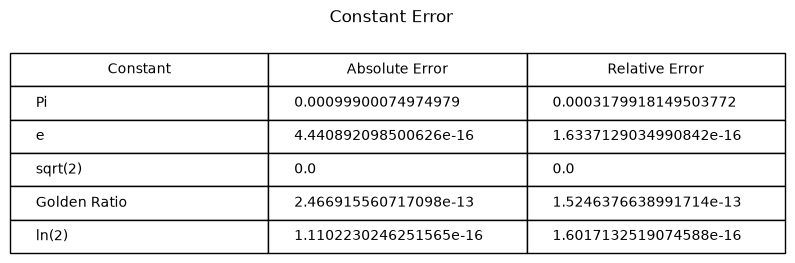

In [68]:
#Table cell values list
values = []

# Pi, Adds row for pi to table data.
values.append(["Pi", np.abs(cf_pi(1000) - np.pi), np.abs((cf_pi(1000) - np.pi) / np.pi)])

# e
values.append(["e", np.abs(cf_e(30) - np.e), np.abs((cf_e(30) - np.e) / np.e)])

#sqrt2
values.append(["sqrt(2)", np.abs(cf_sqrt2(30) - np.sqrt(2)), np.abs((cf_sqrt2(30) - np.sqrt(2)) / np.sqrt(2))])

#golden ratio
values.append(["Golden Ratio", np.abs(cf_golden_ratio(30) - ((1 + np.sqrt(5)) / 2)), np.abs((cf_golden_ratio(30) - ((1 + np.sqrt(5)) / 2)) / ((1 + np.sqrt(5)) / 2))])

# ln2
values.append(["ln(2)", np.abs(cf_ln2(30) - np.log(2)), np.abs((cf_ln2(30) - np.log(2)) / np.log(2))])


# table creation
fig, tableplt = plt.subplots(figsize = (5, .5))
fig.suptitle("Constant Error")

# Turns off plot axis, leaves only table
tableplt.axis("off")

#table display
table = tableplt.table(cellText = values, colLabels= ["Constant", "Absolute Error", "Relative Error"], cellLoc="left")
table.scale(2, 2)

plt.plot()


5. Plot each function against the corresponding built-in function in NumPy over a suitable
interval.

REFERENCES



[1] Wikipedia. William Brouncker, 2nd Viscount Brouncker, section “Brouncker’s formula”.
https://en.wikipedia.org/wiki/William_Brouncker,_2nd_Viscount_Brouncker



[2] J. Baez (2020). Three Phases of Continued Fraction Theory. The n-Category Café,
September 6, 2020. https://golem.ph.utexas.edu/category/2020/09/five_levels_of_
continued_fract.html



[3] The Ramanujan Machine (2020). Catalan’s constant G results. https://ramanujanmachine.
com/wp-content/uploads/2020/06/catalan.pdf



[4] The Ramanujan Machine. From polynomial continued fraction to infinite sums. https:
//ramanujanmachine.com/the-mathematics-of-polynomial-continued-fractions/
from-polynomial-continued-fraction-to-infinite-sums/




[5] The Ramanujan Machine. Results (with links to results for π, e, ln 2, ζ(2), ζ(3) and Catalan’s
constant). https://ramanujanmachine.com/results/

[6] G. Raayoni, S. Gottlieb, Y. Manor, G. Pisha, Y. Harris, U. Mendlovic, D. Haviv, Y. Hadad
and I. Kaminer (2021). Generating conjectures on fundamental constants with the Ramanu-
jan Machine. Nature, 590, 67–73. https://doi.org/10.1038/s41586-021-03229-4
6


[7] Python Software Foundation. fractions — Rational numbers, Python documentation. https:
//docs.python.org/3/library/fractions.html



[8] mpmath: a Python library for arbitrary-precision floating-point arithmetic
